<a href="https://colab.research.google.com/github/25523264-ux/fsd_Linear_kelompok3/blob/main/A_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bagian A: Linear Regression

## A1. Deskripsi Dataset

**Sumber:** folder `sample_data` di Google Colab (`california_housing_train.csv`).
Dataset ini berasal dari sensus penduduk California tahun 1990 (Pace & Barry, 1997).
Deskripsi fitur: https://developers.google.com/machine-learning/crash-course/california-housing-data-description

**Unit observasi:** satu baris = satu *block group* (wilayah kecil sensus), bukan satu rumah.

**Ukuran:** 17.000 baris dan 9 kolom (8 fitur + 1 target).

| Kolom | Arti |
|---|---|
| `longitude` | Garis bujur lokasi (makin negatif = makin ke barat) |
| `latitude` | Garis lintang lokasi (makin besar = makin ke utara) |
| `housing_median_age` | Median usia bangunan di wilayah tersebut (tahun) |
| `total_rooms` | Total jumlah ruangan di wilayah tersebut |
| `total_bedrooms` | Total jumlah kamar tidur di wilayah tersebut |
| `population` | Jumlah penduduk di wilayah tersebut |
| `households` | Jumlah rumah tangga di wilayah tersebut |
| `median_income` | Median pendapatan rumah tangga (satuan: $10.000) |
| **`median_house_value`** | **Target:** median harga rumah (USD), numerik kontinu |

**Tujuan:** memprediksi `median_house_value` dari 8 fitur lainnya menggunakan Linear Regression.

In [1]:
import pandas as pd

df = pd.read_csv('/content/sample_data/california_housing_train.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


meng-import sumber data set dari folder sample_data di Google Colab

- Bagian dari A1 : memastikan jumlah baris dan kolom

In [2]:
print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])
df.info()

Jumlah baris : 17000
Jumlah kolom : 9
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB


- Bagian dari A1 : statistik singkat dari target, untuk memahami karakteristik dan sebaran nilai dari variabel yang ingin diprediksi

In [3]:
df['median_house_value'].describe()

,median_house_value
count,17000.000000
mean,207300.912353
std,115983.764387
min,14999.000000
25%,119400.000000
50%,180400.000000
75%,265000.000000
max,500001.000000


- Bagian dari A1 : Import library matplotlib (untuk fondasi dasar untuk membuat dan mengatur tampilan grafik) dan seaborn (untuk mempermudah pembuatan grafik statistik yang tampilannya lebih rapi dan menarik)

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

## A2. Eksplorasi dan Visualisasi Data

Langkah ini bertujuan memahami sebaran data, hubungan antar variabel, dan potensi masalah (outlier, korelasi tinggi antar fitur) sebelum modeling.

- bagian dari A2 : statistik deskriptif, memberikan ringkasan angka untuk melihat gambaran umum seluruh fitur numerik.

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,17000.0,-119.562108,2.005166,-124.3500,-121.790000,-118.4900,-118.000,-114.3100
latitude,17000.0,35.625225,2.137340,32.5400,33.930000,34.2500,37.720,41.9500
housing_median_age,17000.0,28.589353,12.586937,1.0000,18.000000,29.0000,37.000,52.0000
total_rooms,17000.0,2643.664412,2179.947071,2.0000,1462.000000,2127.0000,3151.250,37937.0000
total_bedrooms,17000.0,539.410824,421.499452,1.0000,297.000000,434.0000,648.250,6445.0000
population,17000.0,1429.573941,1147.852959,3.0000,790.000000,1167.0000,1721.000,35682.0000
households,17000.0,501.221941,384.520841,1.0000,282.000000,409.0000,605.250,6082.0000
median_income,17000.0,3.883578,1.908157,0.4999,2.566375,3.5446,4.767,15.0001
median_house_value,17000.0,207300.912353,115983.764387,14999.0000,119400.000000,180400.0000,265000.000,500001.0000


**Temuan statistik deskriptif:**
- **Ukuran data:** setiap kolom berisi 17.000 nilai (count sama semua), jadi tidak ada indikasi missing value.
- **Target `median_house_value`:** rata-rata sekitar 207.301 USD dan median 180.400 USD. Rata-rata yang lebih besar dari median menunjukkan distribusi condong ke kanan (*right-skewed*). Nilai minimumnya 14.999 dan maksimumnya 500.001. Angka 500.001 adalah batas atas (*capping*), bukan harga sebenarnya.
- **`median_income`:** rata-rata 3,88 (sekitar 38.800 USD) dengan median 3,54. Nilai maksimumnya 15,0001, jauh di atas kuartil ketiga (4,77), sehingga ada blok dengan pendapatan sangat tinggi.
- **`total_rooms`, `total_bedrooms`, `population`, `households`:** nilai maksimumnya jauh di atas persentil 75. Contohnya `total_rooms` maksimum 37.937 padahal kuartil ketiganya 3.151, dan `population` maksimum 35.682 padahal kuartil ketiganya 1.721. Ini menandakan **outlier** yang akan ditangani di A3.
- **`housing_median_age`:** berkisar 1 sampai 52 tahun. Nilai maksimum 52 kemungkinan juga batas atas (*capping*) pada data.
- **`longitude` dan `latitude`:** berkisar -124,35 sampai -114,31 dan 32,54 sampai 41,95, sesuai wilayah California.
- **Skala antar fitur sangat berbeda** (misalnya `median_income` satuan, `total_rooms` ribuan), sehingga scaling berguna untuk membandingkan koefisien.

- bagian dari A2 : histogram target, untuk melihat sebarandan pola distribusi harga rumah (variabel target)

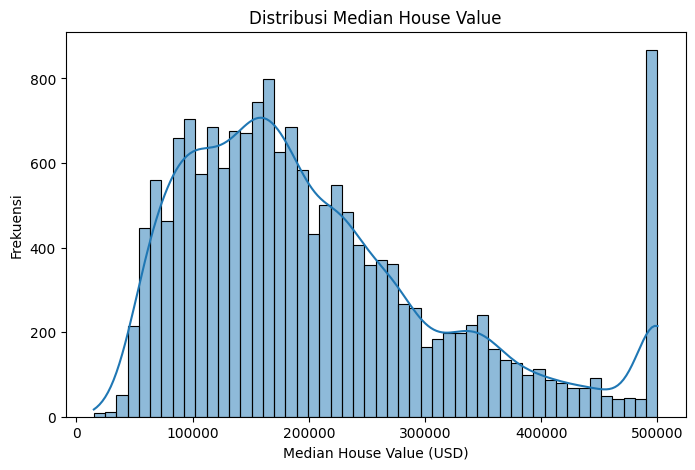

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title('Distribusi Median House Value')
plt.xlabel('Median House Value (USD)')
plt.ylabel('Frekuensi')
plt.show()

**Temuan histogram target:**
- Distribusi `median_house_value` condong ke kanan (*right-skewed*): sebagian besar blok berharga sekitar 100.000 sampai 250.000 USD, dengan puncak sekitar 150.000 sampai 200.000 USD. Makin tinggi harganya, makin sedikit bloknya.
- Ada lonjakan tajam di sisi paling kanan (sekitar 500.000 USD) dengan frekuensi sekitar 870, tertinggi di seluruh histogram. Ini bukan pola alami, melainkan akibat data dibatasi (*capped*) di 500.001, sehingga semua blok dengan harga lebih tinggi tercatat sebagai 500.001.
- Ada bukit kecil di sekitar 350.000 USD, menandakan sebagian blok berada di segmen harga yang lebih tinggi.
- Implikasi: distribusi target tidak normal dan ada efek *capping*, sehingga nilai capped perlu ditangani di A3.

- bagian dari A2 : Heatmap Korelasi, mengukur seberapa kuat hubungan linear antar variabel (nilai berkisar dari -1 hingga +1).

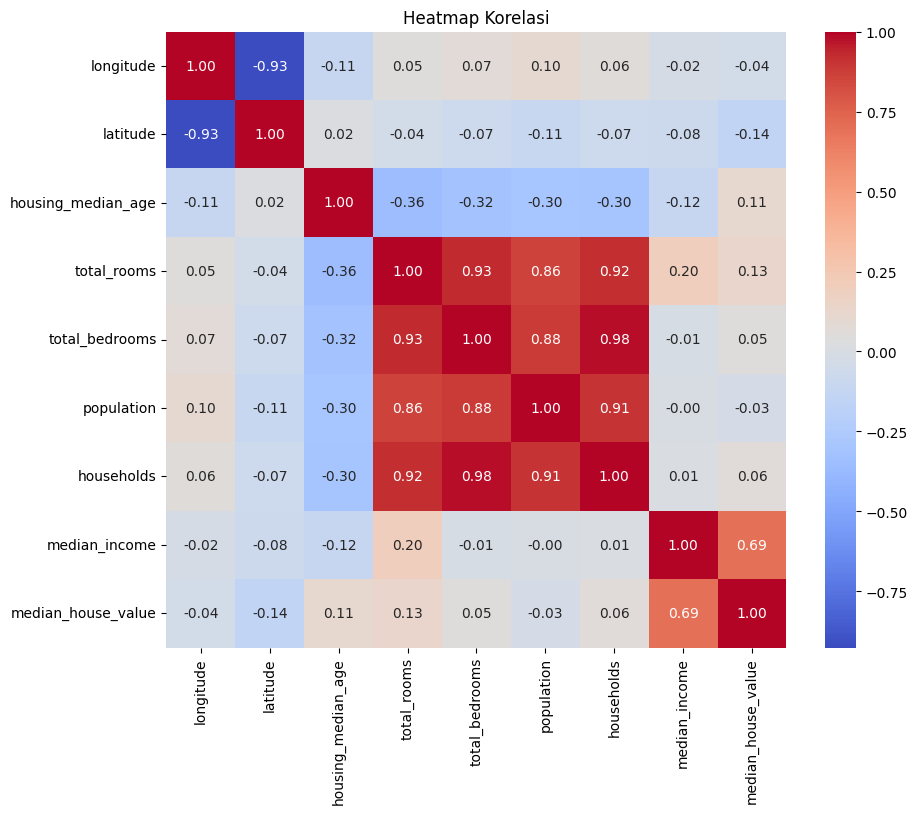

In [7]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Heatmap Korelasi')
plt.show()

**Temuan heatmap korelasi:**
- **Hubungan fitur dengan target:** `median_income` berkorelasi positif paling kuat dengan `median_house_value` (**0,69**). Fitur lain lemah: `latitude` -0,14, `total_rooms` 0,13, `housing_median_age` 0,11, `households` 0,06, `total_bedrooms` 0,05, `longitude` -0,04, dan `population` -0,03.
- **Multikolinearitas:** `total_rooms`, `total_bedrooms`, `population`, dan `households` saling berkorelasi sangat tinggi (0,86 sampai 0,98). Yang tertinggi adalah `total_bedrooms` dengan `households` (0,98). Keempatnya mengukur hal serupa, yaitu ukuran blok, sehingga berisiko membuat koefisien regresi tidak stabil. Ini ditangani di A4.
- **Lokasi:** `longitude` dan `latitude` berkorelasi negatif sangat kuat (-0,93), karena garis pantai California membentang miring dari barat laut ke tenggara.
- `housing_median_age` berkorelasi negatif sedang dengan `total_rooms`, `total_bedrooms`, `population`, dan `households` (sekitar -0,30 sampai -0,36), artinya blok yang lebih tua cenderung lebih kecil.

- bagian dari A2 : scatter plot vs target, untuk melihat pola hubungan langsung antara satu variabel independen (fitur) dengan variabel target secara visual.

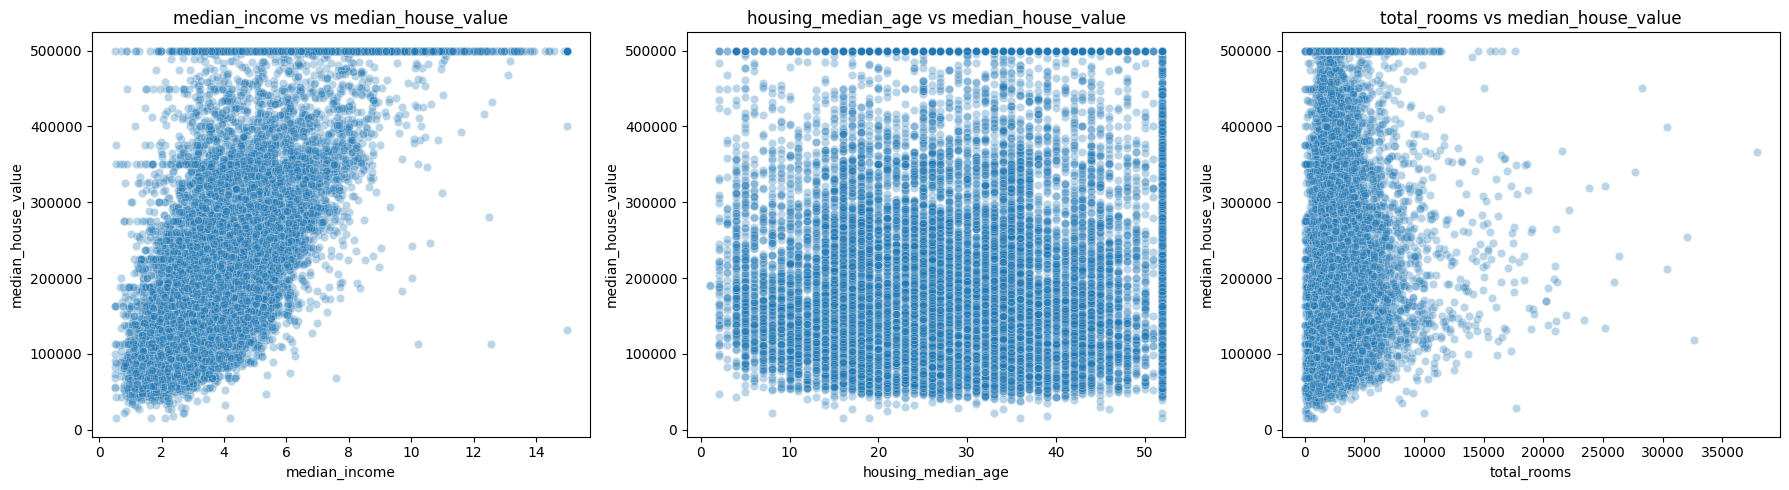

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['median_income', 'housing_median_age', 'total_rooms']):
    sns.scatterplot(data=df, x=col, y='median_house_value', alpha=0.3, ax=ax)
    ax.set_title(f'{col} vs median_house_value')
plt.tight_layout()
plt.show()

**Temuan scatter plot:**
- **`median_income` vs target:** ada tren naik yang jelas, makin tinggi pendapatan makin mahal rumahnya, sesuai korelasi 0,69. Sebaran titik melebar pada pendapatan tinggi, artinya variasi harga makin besar (indikasi heteroskedastisitas). Terlihat garis horizontal di 500.000 akibat *capping*, serta garis samar di sekitar 450.000 dan 350.000 yang menandakan nilai harga yang berulang.
- **`housing_median_age` vs target:** tidak ada pola yang jelas, titik tersebar merata di semua rentang harga. Titik tersusun dalam kolom-kolom karena usia bernilai bulat, dan menumpuk di usia 52 tahun, yang mengindikasikan data juga dibatasi di 52. Garis *capping* di 500.000 juga terlihat.
- **`total_rooms` vs target:** sebagian besar blok memiliki `total_rooms` di bawah sekitar 10.000, dan hanya sedikit yang sangat besar (sampai lebih dari 35.000). Tidak ada pola linear yang jelas, harga tinggi justru banyak pada blok dengan jumlah ruangan kecil sampai menengah. Titik-titik ekstrem di kanan adalah outlier yang akan ditangani di A3.

## A3. Preprocessing

Langkah: (1) cek missing value, (2) cek dan hapus duplikat, (3) tangani outlier, (4) encoding, (5) scaling.

(1) cek missing value, karena jika ada missing value dapat membuat model error atau bias.




In [9]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


**Temuan:** semua 9 kolom bernilai 0 missing value. Dataset sudah lengkap, jadi **tidak perlu imputasi maupun penghapusan baris** akibat data kosong.

(2) cek dan hapus data duplikat, karena data duplikat dapat membuat satu observasi dihitung berkali-kali dan menggelembungkan performa model.

In [10]:
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Ukuran data sekarang :", df.shape)

Jumlah baris duplikat: 0
Ukuran data sekarang : (17000, 9)


**Temuan:** jumlah baris duplikat adalah **0** dan ukuran data tetap (17.000, 9). Setiap baris unik, sehingga tidak ada observasi yang terhitung ganda dan **tidak ada baris yang dihapus**. Kode `drop_duplicates()` tetap dijalankan sebagai langkah pengaman.

(3) tangani outlier, outlier dideteksi dengan metode IQR (nilai di luar Q1 - 1,5×IQR dan Q3 + 1,5×IQR) pada fitur yang distribusinya ekstrem.

In [11]:
cols_outlier = ['total_rooms', 'total_bedrooms', 'population', 'households']

Q1 = df[cols_outlier].quantile(0.25)
Q3 = df[cols_outlier].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

jumlah_outlier = ((df[cols_outlier] < lower) | (df[cols_outlier] > upper)).sum()
print("Jumlah outlier per fitur:")
print(jumlah_outlier)
print("\nJumlah baris dengan target capped (>= 500001):",
      (df['median_house_value'] >= 500001).sum())

Jumlah outlier per fitur:
total_rooms       1076
total_bedrooms    1074
population        1015
households        1032
dtype: int64

Jumlah baris dengan target capped (>= 500001): 814


**Temuan deteksi outlier (metode IQR):**

| Fitur | Jumlah outlier | Proporsi dari 17.000 baris |
|---|---|---|
| `total_rooms` | 1.076 | sekitar 6,3% |
| `total_bedrooms` | 1.074 | sekitar 6,3% |
| `population` | 1.015 | sekitar 6,0% |
| `households` | 1.032 | sekitar 6,1% |

- Keempat fitur ukuran blok memiliki sekitar 6% nilai di luar batas IQR, jumlahnya hampir sama. Ini konsisten dengan korelasi antarfitur yang sangat tinggi (0,86 sampai 0,98): blok yang besar menjadi outlier di semua fitur sekaligus.
- Ada **814 baris** dengan target `median_house_value` bernilai 500.001 (sekitar 4,8% data). Ini nilai batas atas (*censored*), sama dengan lonjakan di histogram A2.
- Karena outlier fitur mencapai sekitar 6% data, menghapusnya akan membuang banyak baris. Penanganannya dijelaskan di bawah.

**Keputusan Penanganan Outlier**

In [12]:
# 1. Hapus baris target capped
df = df[df['median_house_value'] < 500001].copy()

# 2. Clip outlier fitur (batas dihitung ulang setelah baris dihapus)
Q1 = df[cols_outlier].quantile(0.25)
Q3 = df[cols_outlier].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df[cols_outlier] = df[cols_outlier].clip(lower=lower, upper=upper, axis=1)

print("Ukuran data setelah outlier ditangani:", df.shape)
df[cols_outlier].describe().T

Ukuran data setelah outlier ditangani: (16186, 9)


,count,mean,std,min,25%,50%,75%,max
total_rooms,16186.0,2428.157513,1382.248447,2.0,1453.00,2113.0,3124.00,5630.500
total_bedrooms,16186.0,505.486478,288.202414,2.0,298.00,435.0,650.75,1179.875
population,16186.0,1353.594403,772.571049,3.0,799.25,1180.0,1743.75,3160.500
households,16186.0,471.384283,265.758996,2.0,283.00,410.0,607.00,1093.000


**Keputusan penanganan outlier:**
1. **Baris dengan target = 500.001 dihapus.** Nilai ini bukan harga sebenarnya, tetapi batas atas data (*censored*). Jika dipertahankan, garis regresi akan tertarik ke nilai yang tidak nyata.
2. **Outlier pada fitur di-*clip* (winsorizing) ke batas IQR**, bukan dihapus. Menghapusnya akan membuang banyak baris, sedangkan outlier di sini kemungkinan blok berpenduduk padat yang valid, bukan kesalahan data. Clipping mengurangi pengaruh ekstrem tanpa mengurangi jumlah data.

## A4. Pemilihan Fitur

Fitur dipilih dengan tiga analisis: (1) korelasi dengan target, (2) multikolinearitas dengan VIF, (3) skor F dari `SelectKBest`.

In [13]:
df.corr()['median_house_value'].drop('median_house_value').sort_values(ascending=False)

,median_house_value
median_income,0.645729
total_rooms,0.179181
households,0.111203
total_bedrooms,0.088778
housing_median_age,0.068057
population,0.008609
longitude,-0.043938
latitude,-0.150570


**Temuan:** `median_income` memiliki korelasi terkuat dengan target (**0,65**). Fitur lain jauh lebih lemah: `total_rooms` 0,18, `households` 0,11, `total_bedrooms` 0,09, `housing_median_age` 0,07, `population` 0,01, `longitude` -0,04, dan `latitude` -0,15. Angka ini sedikit berbeda dari heatmap di A2 (0,69) karena dihitung setelah baris target *capped* dihapus.

Fitur dipilih dengan analisis: (1) korelasi dengan target,

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

fitur_awal = ['longitude', 'latitude', 'housing_median_age', 'total_rooms',
              'total_bedrooms', 'population', 'households', 'median_income']

X_vif = add_constant(df[fitur_awal])
vif = pd.DataFrame({
    'fitur': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
}).query("fitur != 'const'").sort_values('VIF', ascending=False)
vif

,fitur,VIF
7,households,33.126692
5,total_bedrooms,32.934962
4,total_rooms,13.170843
2,latitude,9.323926
1,longitude,8.978535
6,population,6.060375
8,median_income,2.078189
3,housing_median_age,1.335359


2. Multikolinearitas (VIF)
*Variance Inflation Factor* mengukur seberapa besar suatu fitur dapat diprediksi oleh fitur lain. VIF > 10 umumnya dianggap multikolinearitas serius, yang membuat koefisien regresi tidak stabil dan sulit diinterpretasikan.

**Temuan (2) :** `households` (33,1) dan `total_bedrooms` (32,9) memiliki VIF jauh di atas 10, disusul `total_rooms` (13,2), sehingga ketiganya mengalami multikolinearitas serius. `latitude` (9,3) dan `longitude` (9,0) mendekati ambang 10 karena saling berkorelasi. `population` (6,1) tergolong sedang, sedangkan `median_income` (2,1) dan `housing_median_age` (1,3) aman.

In [15]:
from sklearn.feature_selection import SelectKBest, f_regression

selector = SelectKBest(score_func=f_regression, k='all')
selector.fit(df[fitur_awal], df['median_house_value'])

skor = pd.DataFrame({'fitur': fitur_awal, 'skor_F': selector.scores_}).sort_values('skor_F', ascending=False)
skor

,fitur,skor_F
7,median_income,11574.212346
3,total_rooms,536.838185
1,latitude,375.422654
6,households,202.638265
4,total_bedrooms,128.569165
2,housing_median_age,75.308760
0,longitude,31.304072
5,population,1.199670


### 3. SelectKBest (pembanding)
**Temuan:** skor F tertinggi dimiliki `median_income` (11.574), jauh di atas fitur lain, sejalan dengan hasil korelasi. Berikutnya `total_rooms` (537), `latitude` (375), `households` (203), dan `total_bedrooms` (129). `population` (1,2) paling rendah, artinya hampir tidak menjelaskan variasi harga.

### Keputusan akhir pemilihan fitur
**Dipertahankan:**
- `median_income`: korelasi (0,65) dan skor F (11.574) terkuat terhadap target.
- `households`: mewakili ukuran blok. Dari empat fitur yang saling tumpang tindih (`total_rooms`, `total_bedrooms`, `population`, `households`), hanya satu dipertahankan untuk mengurangi multikolinearitas. VIF-nya akan dihitung ulang setelah tiga lainnya dibuang.
- `housing_median_age`: VIF rendah (1,3) dan memberi informasi usia bangunan.
- `latitude` dan `longitude`: VIF mendekati ambang (9,3 dan 9,0) tetapi masih di bawah 10, dan lokasi geografis sangat memengaruhi harga rumah. Koefisien keduanya tidak diinterpretasikan terpisah.

**Dibuang:**
- `total_rooms`, `total_bedrooms`: VIF di atas 10 dan redundan dengan `households`.
- `population`: skor F paling rendah (1,2), korelasi dengan target hampir nol, dan redundan dengan fitur ukuran blok.

In [16]:
fitur_terpilih = ['longitude', 'latitude', 'housing_median_age', 'households', 'median_income']

X = df[fitur_terpilih]
y = df['median_house_value']

print("Fitur terpilih:", fitur_terpilih)
print("Ukuran X:", X.shape, "| Ukuran y:", y.shape)

Fitur terpilih: ['longitude', 'latitude', 'housing_median_age', 'households', 'median_income']
Ukuran X: (16186, 5) | Ukuran y: (16186,)


## A5. Pembagian Data
Data dibagi 80% latih dan 20% uji dengan `random_state=42` supaya hasil dapat direproduksi.

In [17]:
from sklearn.model_selection import train_test_split

X = df[fitur_terpilih]
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (12948, 5) | Data uji: (3238, 5)


## A6. Pemodelan Linear Regression
Model dilatih pada data latih. Koefisien ditampilkan dalam satuan asli agar mudah diinterpretasikan, dan dalam bentuk standardisasi agar bisa dibandingkan antar fitur.

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

model = LinearRegression()
model.fit(X_train, y_train)

koef = pd.DataFrame({'fitur': fitur_terpilih, 'koefisien': model.coef_})
print("Intercept:", model.intercept_)
display(koef)

# Koefisien terstandardisasi (untuk membandingkan pengaruh antar fitur)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
model_s = LinearRegression().fit(X_train_s, y_train)
koef_std = pd.DataFrame({'fitur': fitur_terpilih, 'koef_standar': model_s.coef_}) \
             .sort_values('koef_standar', key=abs, ascending=False)
display(koef_std)

Intercept: -3410403.9550691973


,fitur,koefisien
0,longitude,-40153.473481
1,latitude,-38872.085799
2,housing_median_age,1117.598562
3,households,40.386794
4,median_income,37220.747916


,fitur,koef_standar
1,latitude,-83432.828484
0,longitude,-80536.299997
4,median_income,58967.829782
2,housing_median_age,14040.935099
3,households,10766.937443


## A7. Evaluasi Model
Metrik dihitung pada data latih dan data uji untuk mendeteksi overfitting.

In [19]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def hitung(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

hasil = pd.DataFrame({'Latih': hitung(y_train, y_pred_train),
                      'Uji': hitung(y_test, y_pred_test)})
hasil

,Latih,Uji
MAE,4.838362e+04,4.741529e+04
MSE,4.132204e+09,4.056362e+09
RMSE,6.428222e+04,6.368957e+04
R2,5.722296e-01,5.671234e-01


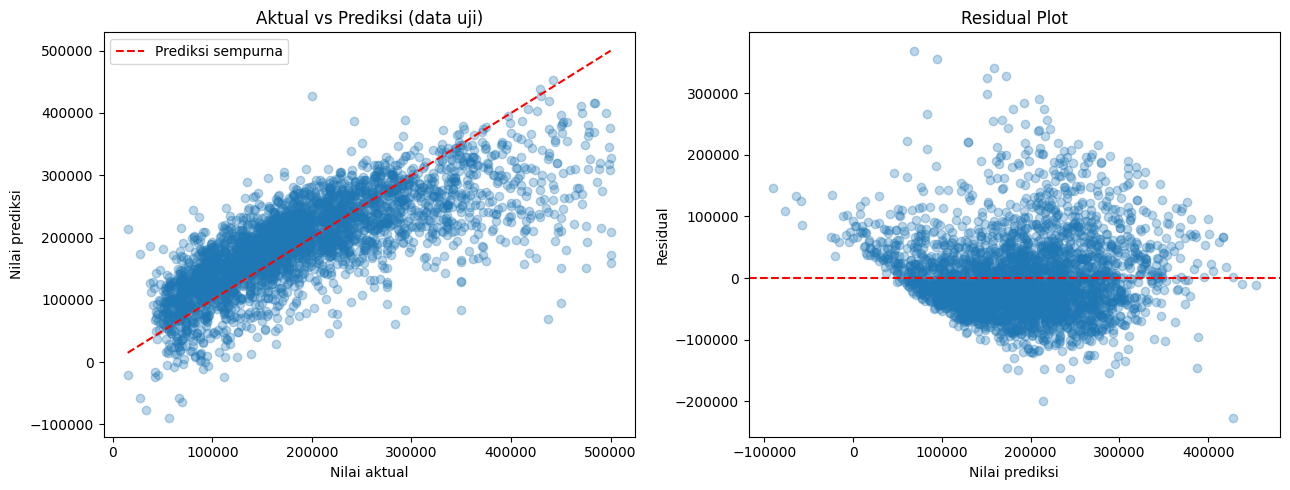

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Aktual vs prediksi
ax[0].scatter(y_test, y_pred_test, alpha=0.3)
lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, 'r--', label='Prediksi sempurna')
ax[0].set_xlabel('Nilai aktual'); ax[0].set_ylabel('Nilai prediksi')
ax[0].set_title('Aktual vs Prediksi (data uji)'); ax[0].legend()

# Residual plot
residual = y_test - y_pred_test
ax[1].scatter(y_pred_test, residual, alpha=0.3)
ax[1].axhline(0, color='r', linestyle='--')
ax[1].set_xlabel('Nilai prediksi'); ax[1].set_ylabel('Residual')
ax[1].set_title('Residual Plot')

plt.tight_layout(); plt.show()

## A8. Analisis Performa

**Kemampuan prediksi.** R² data uji = **X**, artinya model menjelaskan ±X% variasi harga rumah. RMSE = **X** dolar, jadi rata-rata prediksi meleset sekitar segitu dari harga sebenarnya.

**Overfitting/underfitting.** Metrik latih (R² = X, RMSE = X) dan uji (R² = X, RMSE = X) hampir sama, sehingga tidak ada overfitting. Karena R² tidak terlalu tinggi, model cenderung *underfitting* ringan: hubungan fitur dengan harga tidak sepenuhnya linear.

**Fitur paling berpengaruh.** Berdasarkan koefisien terstandardisasi, `median_income` paling kuat, diikuti **(isi dari output)**.

**Keterbatasan.**
1. Asumsi linearitas terlalu sederhana untuk data harga rumah.
2. Harga pada dataset ini di-*cap* di sekitar 500.000, yang tampak sebagai garis lurus pada residual plot dan membuat prediksi rumah mahal bias.
3. Latitude dan longitude dipakai sebagai angka linear, padahal efek lokasi bersifat non-linear.
4. Residual yang melebar di harga tinggi (heteroskedastisitas) melanggar asumsi regresi linear.
5. Dataset 1990-an, jadi tidak mewakili kondisi pasar sekarang.